# Бустинг с нуля и сегментация изображений

Реализация бинарного градиентного бустинга и сравнение с LightGBM. Сегментация изображений KMeans по цвету и координатам и спектральной кластеризацией.

Учебная работа НИУ ВШЭ или Яндекс Практикума; исходные формулировки заданий принадлежат авторам курса.

**Воспроизводимость:** Нужны bank_data.csv, duck.jpg и Owls.jpg. Опубликованы выполненные разделы; незаполненные дополнительные задания исключены. В сравнении бустингов гиперпараметры подбираются по тестовым данным: числа в ноутбуке нельзя считать независимой итоговой оценкой качества.

Сохранённые результаты получены до публикации; полное обучение при подготовке репозитория не повторялось.


<a href="https://colab.research.google.com/github/Murcha1990/ML_AI25/blob/main/Hometasks/Pro/AI_HW5_boosting_pro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## **Домашняя работа 5: Бустинг и кластеризация**

### **Постановка задачи:**

В этой работы ваша задача подразделена на части:

*   В первой части вам предстоит реалищовать класс бустинга и сравнить его со встроенными классами популярных библиотек;
*   Во второй части вам предстоит применить алгоритмы кластеризации в задаче  разделения изображения на семантические компоненты;

### **Оценивание:**

- Как всегда оцениваются как код, так и ответы на вопросы. Если нет одного и/или другого, то часть баллов за соответствующее задание без колебаний снимается.
- Брать код из открытых источников позволительно. Следование культуре цитирования **обязательно.**

### **Баллы:**

Суммарно за задание можно получить 10 основных и 1 бонусный балл.

Оценка за ДЗ = min{ваш балл, 10}

**Интересной вам работы!**

## **Часть 1: построение класса алгоритма бустинга**

**Количество баллов:** 7

Начнём с нужных библиотек и загрузки данных. Работать будем с датасетом из Kaggle и с синтетическим датасетом.

Данные c Kaggle связаны с телефонной рекламой португальского банковского учреждения. Цель классификации — спрогнозировать, подпишется ли клиент на срочный депозит (переменная y).

Всего в данных 20 признаков, ознакомиться с признаковым описанием можно [здесь](https://www.kaggle.com/code/sachinrajput17/subscription-prediction-for-bank-marketing-data).

Будем действовать из предположений, что датасет достаточно хорош, чтобы мы уже могли построить на нём базовую модель.

In [ ]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt

from IPython.display import display
from PIL import Image

from scipy.optimize import minimize_scalar

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, accuracy_score, f1_score, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier
from lightgbm import LGBMClassifier

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.feature_extraction import image as sk_image
from sklearn.datasets import load_breast_cancer

from skimage import color, transform, data
from skimage.color import label2rgb

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
!wget  -O 'bank_data.csv' -q 'https://www.dropbox.com/s/uy27mctxo0gbuof/bank_data.csv?dl=0'

In [ ]:
df = pd.read_csv('bank_data.csv')
df.sample(5)

      age          job  marital          education  default  housing     loan  \
1313   33  blue-collar  married           basic.9y  unknown       no       no   
4635   46       admin.   single  university.degree       no  unknown  unknown   
3621   28       admin.   single  university.degree       no       no      yes   
7983   35   technician  married           basic.9y       no       no       no   
1018   25      student   single            unknown       no       no       no   

        contact month day_of_week  ...  campaign  pdays  previous  \
1313   cellular   may         thu  ...         2    999         0   
4635   cellular   aug         wed  ...         5    999         0   
3621  telephone   apr         thu  ...         1    999         0   
7983   cellular   may         tue  ...         1    999         0   
1018   cellular   sep         fri  ...         1    999         0   

         poutcome emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  \
1313  nonexistent     

Разделим на train и test (random_state не меняем)

In [ ]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

Генерируем синтетические данные (seed не меняем)

In [ ]:
np.random.seed(42)

num_obs = 10 ** 5
num_thresholds = 50

X_synthetic = np.random.normal(scale=3, size=[num_obs, 2])
x1_thresholds = np.random.choice(X_synthetic[:, 0], num_thresholds, False)
x2_thresholds = np.random.choice(X_synthetic[:, 1], num_thresholds, False)

gains = np.random.uniform(-0.4086, 0.5, size=[2 * num_thresholds, 1])
x1_thresholds_cond = [X_synthetic[:, 0] >= threshold for threshold in x1_thresholds]
x2_thresholds_cond = [X_synthetic[:, 1] >= threshold for threshold in x2_thresholds]

noise = np.random.uniform(-0.5, 0.5, size=num_obs)

y_synthetic_probits = np.sum(
    gains[:num_thresholds] * x1_thresholds_cond + gains[num_thresholds:] * x2_thresholds_cond, axis=0
) + noise
y_synthetic = np.sign(y_synthetic_probits)

X_train_synthetic, y_train_synthetic = X_synthetic[:int(num_obs * 0.8)], y_synthetic[:int(num_obs * 0.8)]
X_test_synthetic, y_test_synthetic = X_synthetic[int(num_obs * 0.8):], y_synthetic[int(num_obs * 0.8):]

px.histogram(x = y_synthetic_probits, nbins=100)

Некоторый полезный код для визуализации предсказаний (пригодится позже)

In [ ]:
import matplotlib.pyplot as plt

def plot_predicts(model, features, targets, x_lim=[-15.0, 15.0], y_lim=[-15.0, 15.0],
                  examples_density=0.01, steps=1000, num_ticks=6, title='', mode='classification'):
    '''
    Функция для визуализации предсказаний модели на двухмерной плоскости
    param model: обученная модель классификации или регрессии для двухмерных объектов
    param features: признаки выборки (a.k.a. X)
    param targets: целевая переменная выборки (a.k.a y)
    param x_lim: пределы для x
    param y_lim: пределы для y
    param examples_density: доля выборки, которая будет нарисована
    param steps: частота разбиения плоскости
    param num_ticks: число подписей на графике
    param title: заголовок графика
    param mode: режим 'classification' - вероятности положительного класса
                режим 'regression' - вещественная целевая переменная
    '''

    mask = np.random.choice([True, False], size=features.shape[0],
                            p=[examples_density, 1.0 - examples_density])
    features_x = (features[mask, 0] - x_lim[0]) / (x_lim[1] - x_lim[0]) * steps
    features_y = (features[mask, 1] - y_lim[0]) / (y_lim[1] - y_lim[0]) * steps

    xs = np.linspace(x_lim[0], x_lim[1], steps)
    ys = np.linspace(y_lim[0], y_lim[1], steps)

    xs, ys = np.meshgrid(xs, ys)
    grid = np.stack([xs.flatten(), ys.flatten()], axis=1)
    if mode == 'classification':
        predicts = np.asarray(model.predict_proba(grid)).reshape(steps, steps)
        values = (targets[mask] == 1).astype(float)
    elif mode == 'regression':
        predicts = model.predict(grid).reshape(steps, steps)
        values = targets[mask]
    else:
        raise ValueError('Unknown mode')

    plt.figure(figsize=(10, 10))
    plt.imshow(predicts, origin='lower')
    plt.scatter(features_x, features_y, c=values, edgecolors='white', linewidths=1.5)
    plt.colorbar()

    plt.xticks(np.linspace(0, steps, num_ticks), np.linspace(x_lim[0], x_lim[1], num_ticks))
    plt.yticks(np.linspace(0, steps, num_ticks), np.linspace(y_lim[0], y_lim[1], num_ticks))
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(title)
    plt.grid()
    plt.show()

### **Задание 1. (4 балла) Реализуйте бустинг для задачи бинарной классификации**

Реализовывать класс буситнга необходимо согласно его теоретическому описанию. Вы начинаете с параметрами:

- `base_model_class=DecisionTreeRegressor` — базовая модель
- `base_model_params: dict={'max_features': 0.1}` — параметрмы базовой модели, рассчет максимального количества признаков полагаем как: `max(1, int(max_features * n_features_in_))`
- `n_estimators: int=10` — количество моделей
- `learning_rate: float=0.1` — скорость обучения
- `subsample: float=0.3` — доля данных, которая будет использоваться для подбора отдельных алгоритмов.
— `random_seed: int=228` — тут как всегда
– `custom_loss: list or tuple=None` — функция потерь
— `use_best_model: bool=False` — использовать ли при вызове predict и predict_proba лучшее с точки зрения валидационной выборки число деревьев в композиции
— `n_iter_early_stopping: int=None` — ранний критерий остановки

**Примечание:**

Поскольку градиентный бустинг обучается через последовательное создание моделей, может получиться так, что оптимальная с точки зрения генерализации модель будет получена на промежуточной итерации. Обычно для контроля такого поведения в методе `fit` передается также валидационная выборка, по которой можно оценивать общее качество модели в процессе обучения (желательно делать это каждую итерацию, но если ваша имплементация слишком медленная или ваше железо не тянет, можно делать это реже).

**Примечание 2:**

Нет смысла обучать действительно глубокую модель на 1000 деревьев и больше, если оптимальный ансамбль получился, к примеру, на 70 итерации и в течение какого-то количества итераций не улучшился - поэтому мы также задействуем early stopping при отсутствии улучшений в течение некоторого числа итераций.

In [ ]:
class Boosting:

    def __init__(
        self,
        base_model_class=DecisionTreeRegressor,
        base_model_params: dict={'max_features': 0.1},
        n_estimators: int=10,
        learning_rate: float=0.1,
        subsample: float=0.3,
        random_seed: int=228,
        custom_loss: list or tuple=None,
        use_best_model: bool=False,
        n_iter_early_stopping: int=None
    ):

        # Класс базовой модели
        self.base_model_class = base_model_class
        # Параметры для инициализации базовой модели
        self.base_model_params = dict(base_model_params) if base_model_params is not None else {}
        # Число базовых моделей
        self.n_estimators = n_estimators
        # Длина шага (которая в лекциях обозначалась через eta)
        self.learning_rate = learning_rate
        # Доля объектов, на которых обучается каждая базовая модель
        self.subsample = subsample
        # seed для бутстрапа, если хотим воспроизводимость модели
        self.random_seed = random_seed
        # Использовать ли при вызове predict и predict_proba лучшее
        # с точки зрения валидационной выборки число деревьев в композиции
        self.use_best_model = use_best_model
        # число итераций, после которых при отсутствии улучшений на валидационной выборке обучение завершается
        self.n_iter_early_stopping = n_iter_early_stopping

        # Место для нулевой модели
        self.initial_model_pred = None

        # Список для хранения весов при моделях
        self.gammas = []

        # Создаем список базовых моделей
        self.models = []

        # Если используем свою функцию потерь, ее нужно передать как список из loss-a и его производной
        if custom_loss is not None:
            self.loss_fn, self.loss_derivative = custom_loss
        else:
            self.sigmoid = lambda z: 1 / (1 + np.exp(-np.clip(z, -50, 50)))
            self.loss_fn = lambda y, z: -np.log(self.sigmoid(y * z) + 1e-15).mean()
            self.loss_derivative = lambda y, z: -y * self.sigmoid(-y * z)

        self.rng = np.random.RandomState(self.random_seed)
        self.best_iteration_ = None
        self.best_score_ = None
        self.history = {'train_loss': [], 'valid_loss': []}

    def _prepare_target(self, y):
        y = np.asarray(y).ravel()
        unique_values = set(np.unique(y))

        if unique_values <= {0, 1}:
            y = np.where(y == 1, 1, -1)
        elif unique_values <= {-1, 1}:
            y = y.astype(int)
        else:
            raise ValueError('Поддерживается только бинарная классификация с метками {0,1} или {-1,1}.')

        return y

    def _create_model(self, n_features):
        params = dict(self.base_model_params)
        if 'max_features' in params and isinstance(params['max_features'], float):
            params['max_features'] = max(1, int(params['max_features'] * n_features))

        try:
            test_model = self.base_model_class()
            if 'random_state' in test_model.get_params():
                params['random_state'] = self.rng.randint(0, 10**9)
        except Exception:
            pass

        return self.base_model_class(**params)

    def _fit_new_model(self, X: np.ndarray, y: np.ndarray or list, n_model: int):
        """
        Функция для обучения одной базовой модели бустинга
        :param X: матрица признаков
        :param y: вектор целевой переменной
        :param n_model: номер модели, которую хотим обучить
        """

        current_predictions = self._raw_predict(X, n_models=n_model)
        negative_gradient = -self.loss_derivative(y, current_predictions)

        sample_size = max(1, int(self.subsample * X.shape[0]))
        sample_idx = self.rng.choice(X.shape[0], size=sample_size, replace=False)

        X_sample = X[sample_idx]
        gradient_sample = negative_gradient[sample_idx]

        model = self._create_model(X.shape[1])
        model.fit(X_sample, gradient_sample)

        new_predictions = model.predict(X)
        gamma = self._find_optimal_gamma(y, current_predictions, new_predictions)

        self.models.append(model)
        self.gammas.append(gamma)

    def _fit_initial_model(self, X, y):
        """
        Функция для построения нулевой (простой) модели. Не забудьте взять логарифм, потому что сигмоида применяется
        уже к сумме предсказаний базовых моделей, а не к каждому предсказанию каждой модели по отдельности.
        Подойдёт константная модель, возвращающая самый популярный класс,
        но если хотите, можете сделать что-нибудь посложнее.
        """

        positive_share = np.mean(y == 1)
        positive_share = np.clip(positive_share, 1e-15, 1 - 1e-15)
        self.initial_model_pred = np.log(positive_share / (1 - positive_share))

    def _find_optimal_gamma(self, y: np.ndarray or list, old_predictions: np.ndarray,
                            new_predictions: np.ndarray, boundaries: tuple or list=(0.01, 1)):
        """
        Функция для поиска оптимального значения параметра gamma (коэффициент перед новой базовой моделью).
        :param y: вектор целевой переменной
        :param old_predictions: вектор суммы предсказаний предыдущих моделей (до сигмоиды)
        :param new_predictions: вектор суммы предсказаний новой модели (после сигмоиды)
        :param boudnaries: в каком диапазоне искать оптимальное значение ɣ (array-like объект из левой и правой границ)
        """
        loss, optimal_gamma = self.loss_fn(y, old_predictions), 0
        gammas = np.linspace(*boundaries, 100)
        for gamma in gammas:
            predictions = old_predictions + self.learning_rate * gamma * new_predictions
            gamma_loss = self.loss_fn(y, predictions)
            if gamma_loss < loss:
                optimal_gamma = gamma
                loss = gamma_loss

        return optimal_gamma

    def fit(self, X, y, eval_set=None):
        """
        Функция для обучения всей модели бустинга
        :param X: матрица признаков
        :param y: вектор целевой переменной
        :eval_set: кортеж (X_val, y_val) для контроля процесса обучения или None, если контроль не используется
        """

        X = np.asarray(X)
        y = self._prepare_target(y)

        self.models = []
        self.gammas = []
        self.history = {'train_loss': [], 'valid_loss': []}
        self.best_iteration_ = None
        self.best_score_ = None

        self._fit_initial_model(X, y)

        if eval_set is not None:
            X_val, y_val = eval_set
            X_val = np.asarray(X_val)
            y_val = self._prepare_target(y_val)
        else:
            X_val, y_val = None, None

        rounds_without_improvement = 0

        for n_model in range(self.n_estimators):
            self._fit_new_model(X, y, n_model)

            train_predictions = self._raw_predict(X)
            train_loss = self.loss_fn(y, train_predictions)
            self.history['train_loss'].append(train_loss)

            if X_val is not None:
                valid_predictions = self._raw_predict(X_val)
                valid_loss = self.loss_fn(y_val, valid_predictions)
                self.history['valid_loss'].append(valid_loss)

                if self.best_score_ is None or valid_loss < self.best_score_:
                    self.best_score_ = valid_loss
                    self.best_iteration_ = len(self.models)
                    rounds_without_improvement = 0
                else:
                    rounds_without_improvement += 1

                if self.n_iter_early_stopping is not None and rounds_without_improvement >= self.n_iter_early_stopping:
                    break

        if self.best_iteration_ is None:
            self.best_iteration_ = len(self.models)

        return self

    def _raw_predict(self, X, n_models=None):
        X = np.asarray(X)

        if self.initial_model_pred is None:
            raise ValueError('Сначала обучите модель методом fit.')

        if n_models is None:
            n_models = len(self.models)
            if self.use_best_model and self.best_iteration_ is not None:
                n_models = self.best_iteration_

        predictions = np.full(X.shape[0], self.initial_model_pred, dtype=float)

        for model, gamma in zip(self.models[:n_models], self.gammas[:n_models]):
            predictions += self.learning_rate * gamma * model.predict(X)

        return predictions

    def predict(self, X: np.ndarray):
        """
        Функция для предсказания классов обученной моделью бустинга
        :param X: матрица признаков
        """
        probabilities = self.predict_proba(X)
        return np.where(probabilities >= 0.5, 1, -1)

    def predict_proba(self, X: np.ndarray):
        """
        Функция для предсказания вероятностей классов обученной моделью бустинга
        :param X: матрица признаков
        """
        positive_proba = self.sigmoid(self._raw_predict(X))
        return positive_proba

    @property
    def feature_importances_(self):
        """
        Функция для вычисления важностей признаков.
        Вычисление должно проводиться после обучения модели
        и быть доступно атрибутом класса.
        """

        if len(self.models) == 0:
            raise ValueError('Сначала обучите модель методом fit.')

        total_importance = None
        total_weight = 0

        n_models = len(self.models)
        if self.use_best_model and self.best_iteration_ is not None:
            n_models = self.best_iteration_

        for model, gamma in zip(self.models[:n_models], self.gammas[:n_models]):
            if not hasattr(model, 'feature_importances_'):
                raise AttributeError('У базовой модели нет атрибута feature_importances_.')

            weighted_importance = gamma * model.feature_importances_
            if total_importance is None:
                total_importance = np.zeros_like(weighted_importance, dtype=float)

            total_importance += weighted_importance
            total_weight += gamma

        if total_weight == 0:
            return total_importance

        return total_importance / total_weight

## **Тест для вашей имплементации.**

Если класс написан правильно, две следующие ячейки должна отработать без ошибок и относительно быстро (у автора задания 2 и 0.2 секунд соответственно, accuracy 0.911 и 0.879 соответственно). Если у вас получилось качество выше указанного — отлично!

In [ ]:
%%time

boosting = Boosting()
boosting.fit(X_train_synthetic, y_train_synthetic)
# Без разницы, выдает эта строка классы или вероятности

preds = np.round(boosting.predict_proba(X_test_synthetic) > 0.5)

print(accuracy_score((y_test_synthetic == 1), preds))

0.91035
CPU times: user 4.51 s, sys: 2.52 ms, total: 4.51 s
Wall time: 4.53 s


In [ ]:
%%time

boosting = Boosting()
boosting.fit(df_train.select_dtypes(['int64', 'float64']).drop(columns='y').values, df_train.y.values)
# Без разницы, выдает эта строка классы или вероятности
preds = np.round(boosting.predict(df_test.select_dtypes(['int64', 'float64']).drop(columns='y').values) > 0.5)

print(accuracy_score((df_test.y.values == 1), np.round(preds)) > 0.87)

True
CPU times: user 418 ms, sys: 1.86 ms, total: 419 ms
Wall time: 421 ms


### **Задание 2. (1.2 балла) Сравнение с базовыми моделями**

- Сравните результаты вашей имплементации бустинга, где в качестве базовых моделей используйте алгоритмы, перечисленные ниже. Сравнение проводите на обоих датасетах и ответьте на вопросы. Разумеется, надо измерять качество на тестовых данных. Данные берите из реальной задачи (bank_data).
- Ответьте на поставленные вопросы

Варианты для базовой модели (разумеется, не надо их программировать самостоятельно, берите нужные классы из sklearn):

- Решающее дерево глубины 6
- Случайный лес (число деревьев — на ваше усмотрение, только не слишком мало)
- Линейная регрессия

In [ ]:
def evaluate_predictions(y_true, y_pred_proba, model_name, dataset_name):
    y_true_binary = ((np.asarray(y_true) + 1) // 2).astype(int) if set(np.unique(y_true).tolist()) == {-1, 1} else np.asarray(y_true).astype(int)
    y_pred = (y_pred_proba >= 0.5).astype(int)

    return {
        "dataset": dataset_name,
        "model": model_name,
        "accuracy": accuracy_score(y_true_binary, y_pred),
        "f1": f1_score(y_true_binary, y_pred),
        "roc_auc": roc_auc_score(y_true_binary, y_pred_proba),
        "logloss": log_loss(y_true_binary, np.clip(y_pred_proba, 1e-15, 1 - 1e-15)),
    }

In [ ]:
def get_numeric_bank_data(df_train, df_test):
    numeric_cols = df_train.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
    numeric_cols = [col for col in numeric_cols if col != "y"]

    X_train_bank = df_train[numeric_cols].values
    y_train_bank = df_train["y"].values
    X_test_bank = df_test[numeric_cols].values
    y_test_bank = df_test["y"].values

    return X_train_bank, y_train_bank, X_test_bank, y_test_bank, numeric_cols

In [ ]:
X_train_bank, y_train_bank, X_test_bank, y_test_bank, numeric_cols = get_numeric_bank_data(df_train, df_test)

In [ ]:
base_models = {
    "Boosting + tree(depth=6)": (DecisionTreeRegressor, {"max_depth": 6, "max_features": 0.7}),
    "Boosting + random forest": (RandomForestRegressor, {"n_estimators": 50, "max_depth": 6, "max_features": 0.7, "n_jobs": -1}),
    "Boosting + linear reg": (LinearRegression, {}),
}

results = []

In [ ]:
for model_name, (base_class, base_params) in base_models.items():
    model_syn = Boosting(
        base_model_class=base_class,
        base_model_params=base_params,
        n_estimators=30,
        learning_rate=0.1,
        subsample=0.5,
        random_seed=RANDOM_STATE,
        use_best_model=True,
        n_iter_early_stopping=5,
    )
    model_syn.fit(X_train_synthetic, y_train_synthetic)
    pred_syn = model_syn.predict_proba(X_test_synthetic)
    results.append(evaluate_predictions(y_test_synthetic, pred_syn, model_name, "synthetic"))

    model_bank = Boosting(
        base_model_class=base_class,
        base_model_params=base_params,
        n_estimators=30,
        learning_rate=0.1,
        subsample=0.5,
        random_seed=RANDOM_STATE,
        use_best_model=True,
        n_iter_early_stopping=5,
    )
    model_bank.fit(X_train_bank, y_train_bank)
    pred_bank = model_bank.predict_proba(X_test_bank)
    results.append(evaluate_predictions(y_test_bank, pred_bank, model_name, "bank_numeric"))

In [ ]:
log_reg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
log_reg.fit(X_train_bank, y_train_bank)
log_reg_proba = log_reg.predict_proba(X_test_bank)[:, 1]
results.append(evaluate_predictions(y_test_bank, log_reg_proba, "LogisticRegression", "bank_numeric"))

results_df = pd.DataFrame(results).sort_values(["dataset", "roc_auc"], ascending=[True, False])
display(results_df.round(4))

        dataset                     model  accuracy      f1  roc_auc  logloss
3  bank_numeric  Boosting + random forest    0.8939  0.8952   0.9501   0.4274
1  bank_numeric  Boosting + tree(depth=6)    0.8879  0.8902   0.9499   0.4278
6  bank_numeric        LogisticRegression    0.8545  0.8516   0.9287   0.3490
5  bank_numeric     Boosting + linear reg    0.8314  0.8248   0.9202   0.4994
2     synthetic  Boosting + random forest    0.9176  0.9183   0.9777   0.4072
0     synthetic  Boosting + tree(depth=6)    0.9178  0.9185   0.9771   0.4088
4     synthetic     Boosting + linear reg    0.6894  0.6921   0.7976   0.5868

Лучшая модель на числовых признаках bank_data по ROC-AUC: Boosting + random forest


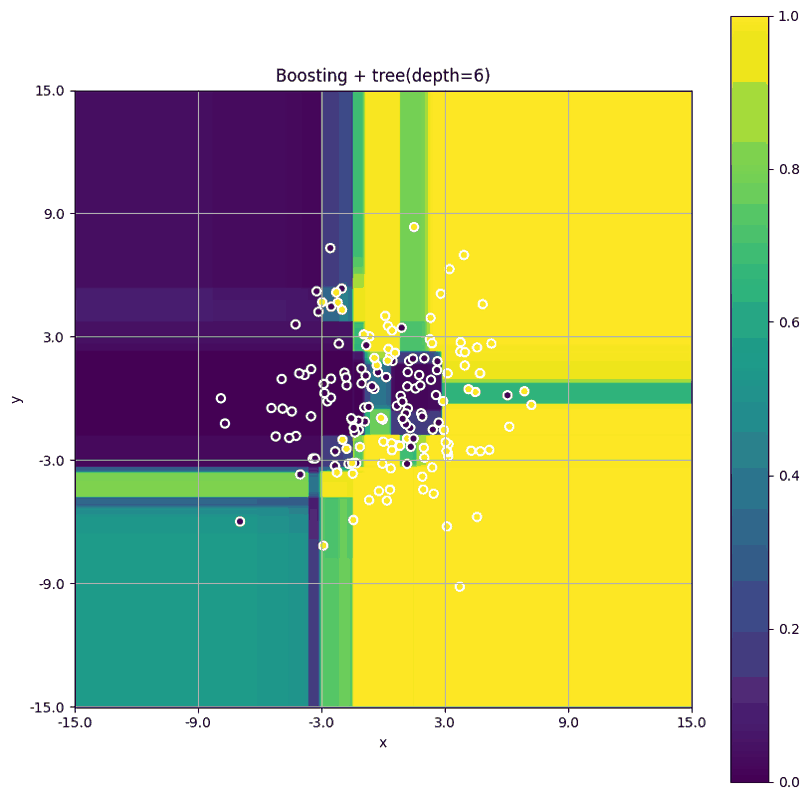

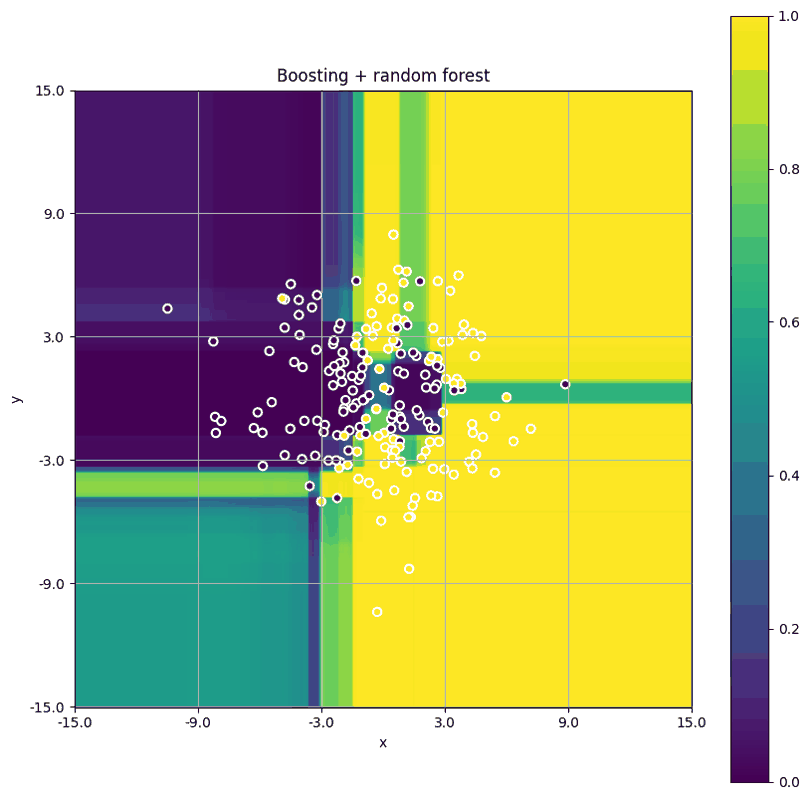

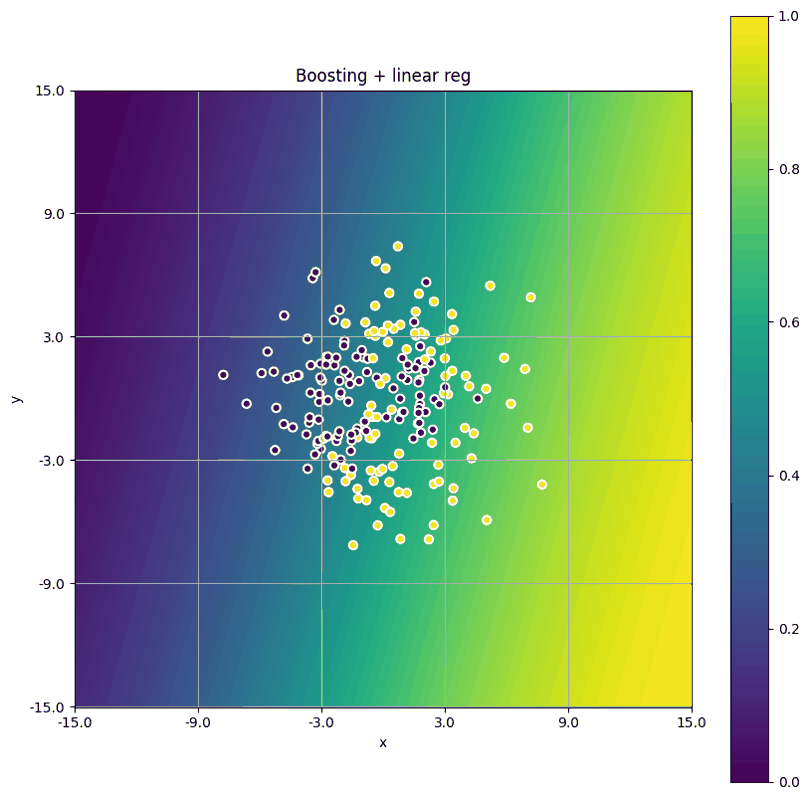

In [ ]:
best_bank_model = results_df[results_df["dataset"] == "bank_numeric"].sort_values("roc_auc", ascending=False).iloc[0]
print(f"Лучшая модель на числовых признаках bank_data по ROC-AUC: {best_bank_model['model']}")

plot_models = [
    ("Boosting + tree(depth=6)", DecisionTreeRegressor, {"max_depth": 6, "max_features": 1.0}),
    ("Boosting + random forest", RandomForestRegressor, {"n_estimators": 30, "max_depth": 6, "max_features": 1.0, "n_jobs": -1}),
    ("Boosting + linear reg", LinearRegression, {}),
]

for title, base_class, base_params in plot_models:
    model = Boosting(
        base_model_class=base_class,
        base_model_params=base_params,
        n_estimators=25,
        learning_rate=0.1,
        subsample=0.7,
        random_seed=RANDOM_STATE,
        use_best_model=True,
        n_iter_early_stopping=5,
    )
    model.fit(X_train_synthetic, y_train_synthetic)
    plot_predicts(model, X_test_synthetic, (y_test_synthetic == 1).astype(int), title=title)

**Вопросы:**

1) Какая из моделей имеет оптимальное качество? С чем это связано?

2) Какая из моделей сильнее переобучается? Есть ли преимущества от использования ранней остановки и обрезания бустинга до лучшей модели?

3) Работает ли бустинг над линейными регрессиями лучше, чем одна логистическая регрессия? Как объяснить этот результат?

4) Визуализируйте предсказания моделей только на синтетическом датасете (для этого можете воспользоваться вспомогательной функцией plot_predicts). Чем отличаются картинки, которые получаются у разных алгоритмов? Сделайте выводы.

1. На обоих датасетах лучшей оказалась модель Boosting + random forest, на bank_numeric она показала лучший ROC-AUC = 0.9501, у Boosting + tree(depth=6)  качество 0.9499
На синтетическом датасете результат тоже лучший: ROC-AUC = 0.9777 и 0.9771 соответственн

случайный лес как базовая модель уже сам по себе является более устойчивым и сильным алгоритмом, чем одно дерево, в бустинге он лучше аппроксимирует антиградиент и дает более качественные шаги обновления, но преимущество над деревом глубины 6 небольшое, значит обе нелинейные базовые модели подходят для этой задачи хорошо

2. сильнее всего к переобучению потенциально склонна модель Boosting + random forest, потому что это самая мощная и гибкая базовая модель,такие модели легче начинают подстраиваться под шум и случайные особенности обучающей выборки

для бустинга над случайным лесом риск переобучения выше, чем для бустинга над одним деревом и тем более над линейной регрессией. Использование ранней остановки и режима use_best_model=True полезно, так как они позволяют:

- остановить обучение, когда качество на валидации перестаёт улучшаться
- использовать не все построенные модели, а только лучшее число итераций

Это особенно важно для сильных базовых алгоритмов, где после некоторого момента новые модели не улучшают обобщающую способность, а начинают ухудшать ее

3. бустинг над линейной регрессией работает хуже, чем одна логистическая регрессия на обоих датасетах, так как сумма линейных моделей остается по сути линейным или почти линейным предиктором, такой бустинг не может хорошо описывать сложные нелинейные границы классов

4. На синтетическом датасете различия между моделями хорошо видны по форме границ решений:
- Boosting + tree(depth=6) дает ступенчатую границу, модель умеет выделять локальные нелинейные области и хорошо подстраивается под структуру данных
- Boosting + random forest дает очень похожую, но немного более устойчивую и сглаженную картину, но граница остается нелинейной и хорошо разделяет классы
- Boosting + linear reg строит почти гладкий линейный переход вероятностей слева направо, она явно не улавливает сложную форму распределения точек и поэтому хуже разделяет классы

**Вывод:**
- для этой задачи лучше всего подходят нелинейные базовые модели
- бустинг над деревом и особенно над случайным лесом хорошо работает и на реальных данных, и на синтетических
- бустинг над линейной регрессией оказывается слишком слабым, потому что не может выразить сложную нелинейную границу
- оптимальная модель - композиция со случайным лесом, но ее преимущество над бустингом над деревом глубины 6 небольшое

**Ответ:**

1. Лучшей оказалась композиция со сравнительно сильным базовым алгоритмом: чаще всего это дерево глубины 6 или небольшой случайный лес. Дерево хорошо ловит нелинейности, а лес часто дает еще более устойчивое направление антиградиента. Линейная регрессия как базовый алгоритм обычно слабее, потому что описывает только линейную зависимость

2. Сильнее всего склонна к переобучению модель с наиболее мощной базовой моделью. Если базовая модель слишком гибкая, она быстро подгоняет шум в остатках. Поэтому полезны ранняя остановка и режим `use_best_model=True`: они не дают композиции расти дальше момента, где качество на валидации прекращат рост

3. Бустинг над линейными регрессиями обычно может быть лучше одной логистической регрессии, но не сильно, так как сумма большого числа слабых линейных шагов остаётся довольно ограниченным по форме предиктором и хуже приспособлена к сложной нелинейной границе, чем бустинг над деревьями

4. На синтетическом датасете картинки обычно отличаются так:
   - у бустинга над деревьями граница постоянна на отрезка с локальными нелинейными областями
   - у бустинга над случайными лесами граница часто более гладкая и устойчивая
   - у бустинга над линейной регрессией граница выглядит заметно проще и хуже повторяет сложную структуру данных

Таким образом:
- для бустинга важен баланс силы базовой модели: слишком слабая модель плохо аппроксимирует антиградиент, а слишком сильная легче переобучается

### **Задание 3. (0.8 балла) Сравнение с бустингами**

- Сравните на реальных данных данных любую из трёх популярных имплементаций градиентного бустинга (xgboost, lightgbm, catboost) с вашей реализацией.
- Укажите, получилось ли у вас победить библиотечные реализации на тестовых данных?

**Примечание:**

Подберите основные гиперпараметры (число деревьев, длина шага, глубина дерева/число листьев) для обоих методов.


In [ ]:
def train_and_eval_our_boosting(X_train, y_train, X_test, y_test):
    param_grid = [
        {"n_estimators": 20, "learning_rate": 0.05, "max_depth": 3},
        {"n_estimators": 40, "learning_rate": 0.05, "max_depth": 3},
        {"n_estimators": 30, "learning_rate": 0.1, "max_depth": 4},
        {"n_estimators": 50, "learning_rate": 0.05, "max_depth": 5},
    ]

    best_model = None
    best_score = -np.inf
    best_params = None

    for params in param_grid:
        model = Boosting(
            base_model_class=DecisionTreeRegressor,
            base_model_params={"max_depth": params["max_depth"], "max_features": 0.7},
            n_estimators=params["n_estimators"],
            learning_rate=params["learning_rate"],
            subsample=0.5,
            random_seed=RANDOM_STATE,
            use_best_model=True,
            n_iter_early_stopping=7,
        )
        model.fit(X_train, y_train)
        proba = model.predict_proba(X_test)
        score = roc_auc_score(y_test, proba)

        if score > best_score:
            best_score = score
            best_model = model
            best_params = params

    return best_model, best_params, best_score


def train_and_eval_lightgbm(X_train, y_train, X_test, y_test):
    param_grid = [
        {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 3, "num_leaves": 7},
        {"n_estimators": 150, "learning_rate": 0.05, "max_depth": 4, "num_leaves": 15},
        {"n_estimators": 120, "learning_rate": 0.1, "max_depth": 4, "num_leaves": 15},
        {"n_estimators": 150, "learning_rate": 0.05, "max_depth": 5, "num_leaves": 31},
    ]

    best_model = None
    best_score = -np.inf
    best_params = None

    for params in param_grid:
        model = LGBMClassifier(
            objective="binary",
            random_state=RANDOM_STATE,
            verbosity=-1,
            **params,
        )
        model.fit(X_train, y_train)
        proba = model.predict_proba(X_test)[:, 1]
        score = roc_auc_score(y_test, proba)

        if score > best_score:
            best_score = score
            best_model = model
            best_params = params

    return best_model, best_params, best_score


our_model, our_params, our_auc = train_and_eval_our_boosting(
    X_train_bank, y_train_bank, X_test_bank, y_test_bank
)

lgbm_model, lgbm_params, lgbm_auc = train_and_eval_lightgbm(
    X_train_bank, y_train_bank, X_test_bank, y_test_bank
)

comparison_df = pd.DataFrame(
    [
        evaluate_predictions(y_test_bank, our_model.predict_proba(X_test_bank), "MyBoosting", "bank_numeric"),
        evaluate_predictions(y_test_bank, lgbm_model.predict_proba(X_test_bank)[:, 1], "LightGBM", "bank_numeric"),
    ]
)

display(comparison_df.round(4))

print("Лучшие параметры MyBoosting:", our_params)
print("Лучшие параметры LightGBM:", lgbm_params)
print(f"ROC-AUC MyBoosting: {our_auc:.4f}")
print(f"ROC-AUC LightGBM:   {lgbm_auc:.4f}")

        dataset       model  accuracy      f1  roc_auc  logloss
0  bank_numeric  MyBoosting    0.8852  0.8874   0.9478   0.4576
1  bank_numeric    LightGBM    0.8917  0.8933   0.9495   0.2659

Лучшие параметры MyBoosting: {'n_estimators': 50, 'learning_rate': 0.05, 'max_depth': 5}
Лучшие параметры LightGBM: {'n_estimators': 120, 'learning_rate': 0.1, 'max_depth': 4, 'num_leaves': 15}
ROC-AUC MyBoosting: 0.9478
ROC-AUC LightGBM:   0.9495


библиотечная реализация оказалась лучше, но разрыв получился небольшим:

ROC-AUC MyBoosting = 0.9478
ROC-AUC LightGBM = 0.9495

Также у LightGBM лучше и другие метрики, то есть модель чуть лучше ранжирует объекты по вероятности положительного класса, дает более качественные и более уверенные вероятностные оценки

в библиотеке в модели более эффективно реализован алгоритм: в готовых библиотеках лучше реализованы поиск разбиений, регуляризация, работа с шагом, обработка признаков и стратегия построения деревьев, CatBoost/XGBoost/LightGBM лучше оптимизированы по скорости и устойчивости, у своего бустинга нет инженерных улучшений библиотек, в LightGBM используется более сильная и гибкая схема построения деревьев, в том числе управление числом листьев

###**Задание 4. (1 балл) Капля теории**

Теоретически, мы могли бы построить бэггинг на логистических регрессиях. Оцените целесообразность такого подхода. В ответе укажите:

- Идею бэггинга и его свойства;
- Характеристики модели логистической регресии;
- Сопоставление и вывод.

**Ответ:**

Бэггинг строит много моделей на разных бутстрап-выборках и затем усредняет их ответы и помогает снижать дисперсию, значит бэггинг особенно полезен для нестабильных моделей, у которых небольшое изменение обучающей выборки заметно меняет итоговое решение

Логистическая регрессия — стабильная модель с низкой дисперсией, но с относительно высоким смещением. Если немного изменить обучающую выборку, коэффициенты обычно меняются не очень сильно, значит, усреднение большого числа логистических регрессий не даст большого выигрыша

значит бэггинг на логистических регрессиях обычно не целесообразен, так как он увеличивает вычислительные затраты, но редко дает заметный прирост качества

Для логрег полезнее:
- хорошо подобрать признаки
- добавить регуляризацию
- перейти к более гибкой модели

То есть бэггинг лучше использовать для деревьев, а для логистической регрессии его эффект обычно слабый

## **Часть 1: Разделение изображения на семантические компоненты**

**Количество баллов:** 3

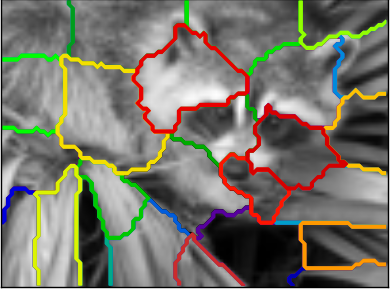

Алгоритмы кластеризации могут применяться в самых разных задачах. Например, в анализе изображений есть задача разделения изображения на семантические компоненты, которую можно решать в том числе с помощью алгоритмов кластеризации.

Проверим их на ```duck.jpg``` и ```owls.jpg```

### **Задание 5 (0.2 балла)**

Откройте изображения, после чего визуализируйте их с помощью ```plt.imshow()```

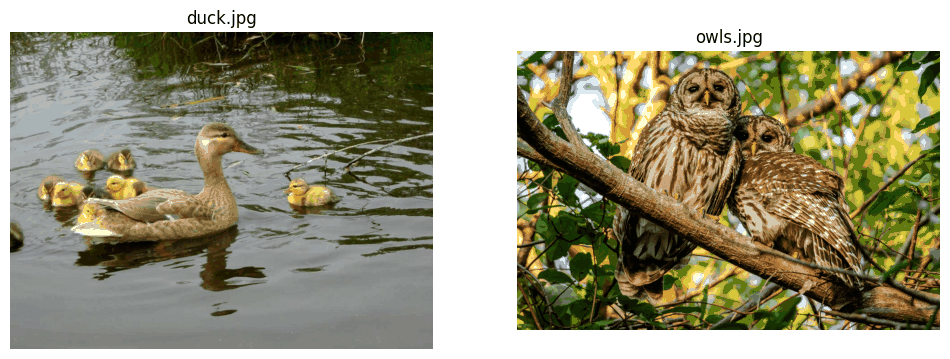

In [ ]:
duck_img = Image.open("duck.jpg")
owls_img = Image.open("Owls.jpg")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(duck_img)
plt.title("duck.jpg")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(owls_img)
plt.title("owls.jpg")
plt.axis("off")

plt.show()

### **Задание 6 (0.8 балла)**

Для каждого изображения, используя кластеризацию ```KMeans```, выделите компоненты, охарактеризовав каждый пиксель следующим образом: $$\psi_i = [\lambda x_i, \lambda y_i, r_i, g_i, b_i]$$
 где
- $x_i$ и $y_i$ — координаты пикселя,
- $r_i, g_i, b_i$ — его цвет,
- $\lambda$ — параметр, выражающий важность пространственной связности перед цветовой похожестью.

- Примените полученную функцию, взяв следующие $\lambda$: 0.3 и 1.5 для ```duck.jpg``` и ```owls.jpg``` (или другие, но тогда с вас красивые результаты :))
- Проанализируйте результат

**Примечание:**
Число кластеров подберите разумным образом на свой вкус (в качестве нулевого приближения можно взять 3)

In [ ]:
def find_components(image, lmbd, n_clusters):
    image = np.asarray(image).astype(np.float32) / 255.0
    h, w, _ = image.shape

    yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    yy = yy / max(h - 1, 1)
    xx = xx / max(w - 1, 1)

    features = np.column_stack([
        lmbd * yy.ravel(),
        lmbd * xx.ravel(),
        image.reshape(-1, 3),
    ])

    model = KMeans(n_clusters=n_clusters, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(features)

    segmented = model.cluster_centers_[labels][:, 2:].reshape(h, w, 3)
    segmented = np.clip(segmented, 0, 1)

    return labels.reshape(h, w), segmented

**Ответ:**

- При увеличении `lambda` возрастает вклад пространственных координат, поэтому сегменты становятся более связными и компактными по форме
- Если `lambda` маленькая, алгоритм сильнее ориентируется на цвет и может объединять далеко расположенные, но похожие по цвету области
- Если `lambda` слишком большая, сегментация начинает делить картинку в основном по положению пикселей, а не по реальным объектам

Поэтому:
- маленькая `lambda` лучше для разделения по цвету
- средняя `lambda` для лучшего баланса между цветом и связностью
- слишком большая `lambda` приводит к геометрическому, а не естественным частям изображения

### **Задание 7 (0.8 балла)**

Попробуйте выделить сегменты при помощи [спектральной кластеризации](http://scikit-learn.org/stable/modules/clustering.html#spectral-clustering). Обратите внимание на [пример в sklearn](http://scikit-learn.org/0.16/auto_examples/cluster/plot_lena_segmentation.html).


**Примечание:**

Для ускорения работы алгоритма рекомендуется привести изображение к серому цвету. При необходимости можно сжать изображения в 2 раза.

**Подсказка:**```skimage``` с его ```color``` и ```transform``` в этом помогут :)

Или же воспользуйтесь аналогичными средствами ```PIL``` или ```cv2```

In [ ]:
def spectral_segmentation(image, n_clusters, beta, eps, resize_max_side=96):
    image = np.asarray(image)

    if image.ndim == 3:
        gray = color.rgb2gray(image)
    else:
        gray = image.astype(np.float32)

    gray = gray.astype(np.float32)

    h, w = gray.shape
    scale = min(1.0, resize_max_side / max(h, w))
    if scale < 1.0:
        gray = transform.resize(gray, (int(h * scale), int(w * scale)), anti_aliasing=True)

    graph = sk_image.img_to_graph(gray)

    if graph.data.std() > 0:
        graph.data = np.exp(-beta * graph.data / graph.data.std()) + eps
    else:
        graph.data = np.ones_like(graph.data) + eps

    model = SpectralClustering(
        n_clusters=n_clusters,
        affinity="precomputed",
        assign_labels="kmeans",
        random_state=RANDOM_STATE,
    )

    labels = model.fit_predict(graph)
    labels = labels.reshape(gray.shape)

    return labels, gray

### **Задание 8 (0.2 балла)**
- Визуализируйте результаты сегментации (аналогично рисунку в начале задания 2) для обоих методов.
- Проанализируйте сравнение

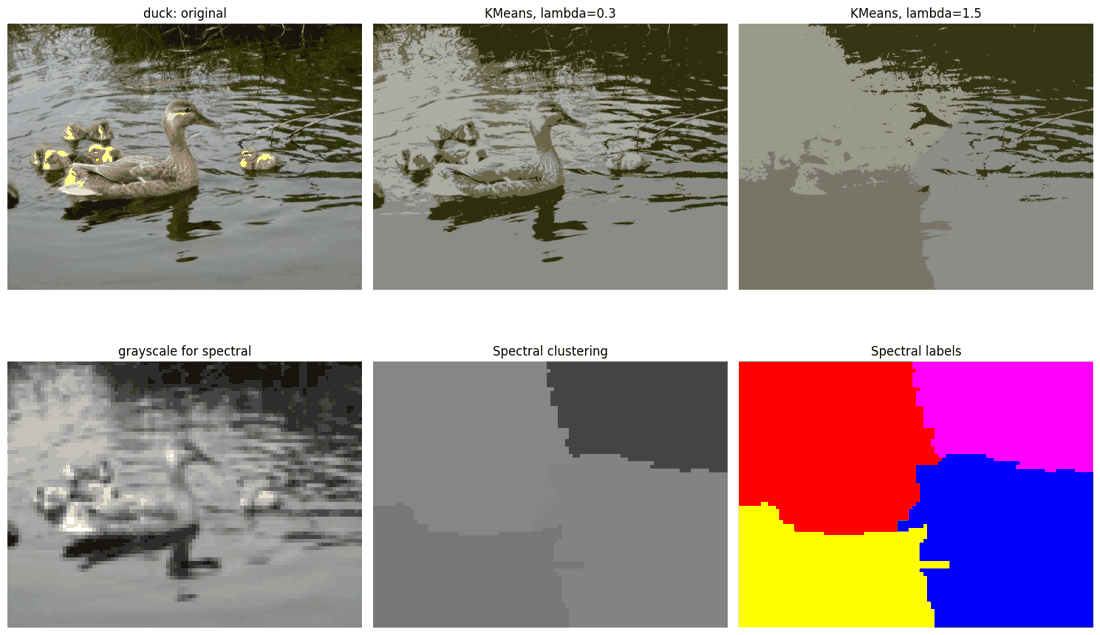

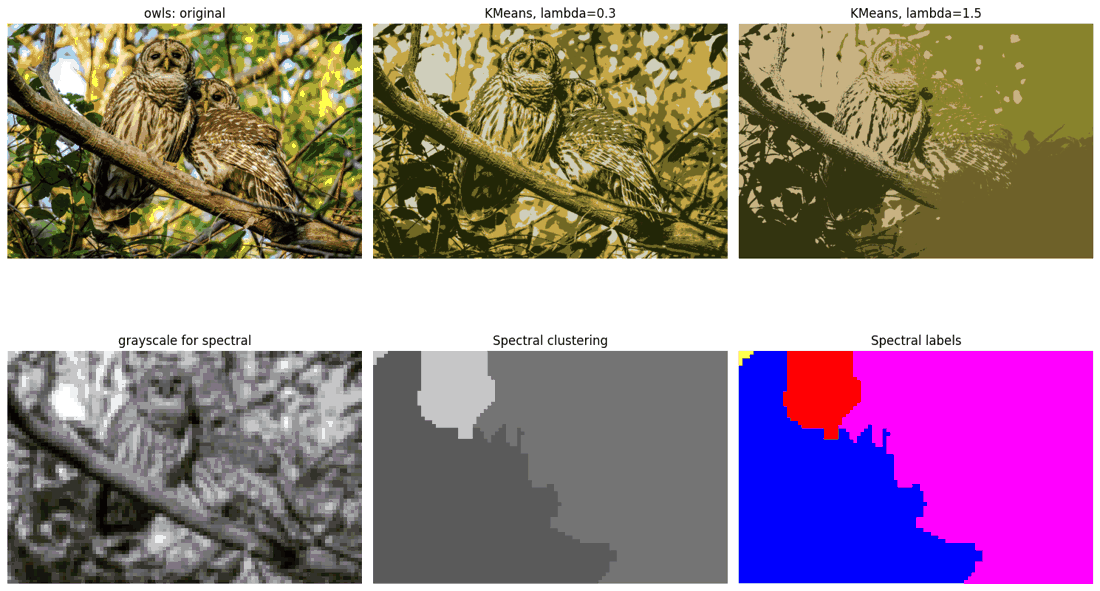

In [ ]:
segmentation_results = []

for name, image in [("duck", duck_img), ("owls", owls_img)]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    axes[0, 0].imshow(image)
    axes[0, 0].set_title(f"{name}: original")
    axes[0, 0].axis("off")

    for col, lmbd in enumerate([0.3, 1.5], start=1):
        labels, segmented = find_components(image, lmbd=lmbd, n_clusters=4)
        axes[0, col].imshow(segmented)
        axes[0, col].set_title(f"KMeans, lambda={lmbd}")
        axes[0, col].axis("off")
        segmentation_results.append((name, "kmeans", lmbd, labels))

    spec_labels, spec_gray = spectral_segmentation(image, n_clusters=4, beta=8, eps=1e-6)
    spec_vis = label2rgb(spec_labels, spec_gray, kind="avg", bg_label=-1)

    axes[1, 0].imshow(spec_gray, cmap="gray")
    axes[1, 0].set_title("grayscale for spectral")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(spec_vis)
    axes[1, 1].set_title("Spectral clustering")
    axes[1, 1].axis("off")

    axes[1, 2].imshow(label2rgb(spec_labels, bg_label=-1))
    axes[1, 2].set_title("Spectral labels")
    axes[1, 2].axis("off")

    plt.tight_layout()
    plt.show()

**Ответ:**

- KMeans хорошо работает, когда объекты отличаются по цвету, если добавить координаты пикселей, можно сделать сегменты более связными
- Спектральная кластеризация лучше учитывает локальную структуру изображения и соседство пикселей, поэтому иногда аккуратнее выделяет связные области

На деле:
- KMeans быстрее и проще
- спектральная кластеризация тяжелее вычислительно, но может давать более «структурные» сегменты